# Toy flow matching

Before touching SD3 I want the RL part working on something I can check by eye. So: a small flow matching model on 2D points with a class condition. Same conventions as SD3: t=1 is noise, t=0 is data, the model predicts velocity.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)

SURFACE, INK, GRID, MUTED = "#fcfcfb", "#52514e", "#e1e0d9", "#c3c2b7"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def style(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)

## Data

8 classes, each one is a short arc on a ring. The class plays the role of the prompt.

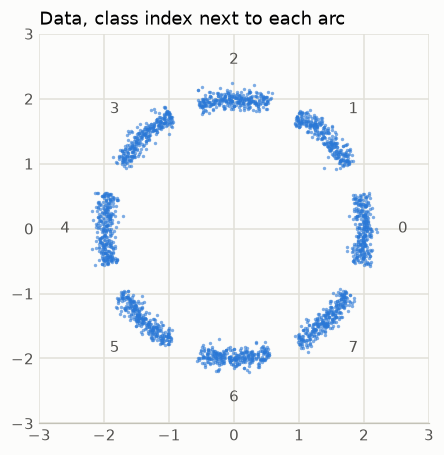

In [2]:
K = 8
RADIUS = 2.0
HALF_ARC = math.pi / K * 0.7
R_STD = 0.08


def sample_data(c):
    center = 2 * math.pi * c / K
    angle = center + (torch.rand(len(c)) * 2 - 1) * HALF_ARC
    radius = RADIUS + R_STD * torch.randn(len(c))
    return torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)


c = torch.arange(K).repeat_interleave(300)
data = sample_data(c)

fig, ax = plt.subplots(figsize=(4.6, 4.6), dpi=110, facecolor=SURFACE)
style(ax, grid="both")
ax.scatter(data[:, 0], data[:, 1], s=5, color=COLORS[0], alpha=0.6, lw=0)
for k in range(K):
    a = 2 * math.pi * k / K
    ax.text(2.6 * math.cos(a), 2.6 * math.sin(a), str(k), ha="center", va="center", color=INK)
ax.set_aspect("equal")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title("Data, class index next to each arc", loc="left")
plt.show()

## Model and training

$x_t = (1 - t)\,x_0 + t\,\varepsilon$, the model is trained to predict $\varepsilon - x_0$.

A small MLP that takes the point, t and the one-hot class.

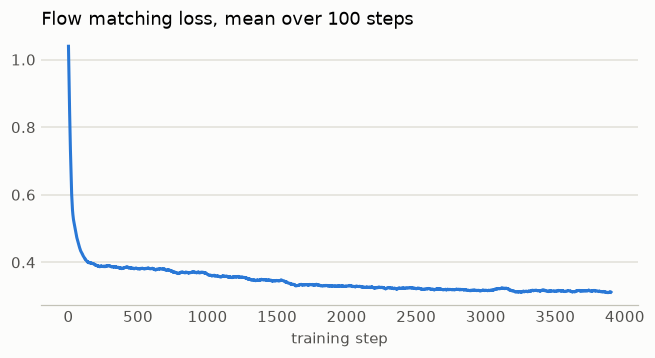

last 200 steps: 0.314


In [3]:
class Velocity(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + 1 + K, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t, c):
        onehot = nn.functional.one_hot(c, K).float()
        return self.net(torch.cat([x, t[:, None], onehot], dim=1))


def train_flow(steps=4000, batch=512, lr=2e-3):
    model = Velocity()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        c = torch.randint(K, (batch,))
        x0 = sample_data(c)
        noise = torch.randn_like(x0)
        t = torch.rand(batch)
        xt = (1 - t)[:, None] * x0 + t[:, None] * noise
        loss = ((model(xt, t, c) - (noise - x0)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses.append(loss.item())
    return model, losses


base, losses = train_flow()

smooth = torch.tensor(losses).unfold(0, 100, 1).mean(dim=1)
fig, ax = plt.subplots(figsize=(7, 3.2), dpi=110, facecolor=SURFACE)
style(ax)
ax.plot(range(len(smooth)), smooth, color=COLORS[0], lw=2)
ax.set_xlabel("training step", color=INK)
ax.set_title("Flow matching loss, mean over 100 steps", loc="left")
plt.show()
print(f"last 200 steps: {sum(losses[-200:]) / 200:.3f}")

The loss levels off around 0.31 and does not go to zero. From a noisy point the model cannot know the exact target, so it learns the average and some error always stays.

## Sampling

Euler steps from t=1 down to t=0.

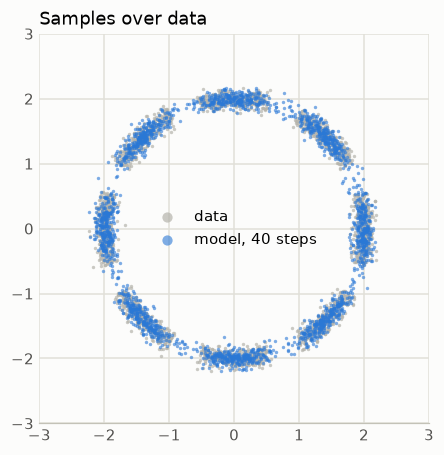

In [4]:
@torch.no_grad()
def sample_ode(model, c, steps=40, noise=None):
    x = torch.randn(len(c), 2) if noise is None else noise.clone()
    ts = torch.linspace(1, 0, steps + 1)
    for t, t_next in zip(ts[:-1], ts[1:]):
        x = x + model(x, t.expand(len(c)), c) * (t_next - t)
    return x


c = torch.arange(K).repeat_interleave(300)
samples = sample_ode(base, c, steps=40)
data = sample_data(c)

fig, ax = plt.subplots(figsize=(4.6, 4.6), dpi=110, facecolor=SURFACE)
style(ax, grid="both")
ax.scatter(data[:, 0], data[:, 1], s=5, color="#b5b4ac", alpha=0.7, lw=0, label="data")
ax.scatter(samples[:, 0], samples[:, 1], s=5, color=COLORS[0], alpha=0.6, lw=0, label="model, 40 steps")
ax.set_aspect("equal")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.legend(frameon=False, loc="center", markerscale=3)
ax.set_title("Samples over data", loc="left")
plt.show()

## How many steps

Three numbers to compare with the data:

- inside: share of points inside their own arc (angle within the arc, radius within 3 std)
- radius std
- angle std: spread along the arc, measured from the middle of the arc

In [5]:
def describe(x, c):
    radius = x.norm(dim=1)
    angle = torch.atan2(x[:, 1], x[:, 0])
    offset = (angle - 2 * math.pi * c / K + math.pi) % (2 * math.pi) - math.pi
    inside = (offset.abs() <= HALF_ARC) & ((radius - RADIUS).abs() <= 3 * R_STD)
    return {
        "inside": inside.float().mean().item(),
        "radius std": radius.std().item(),
        "angle std": offset.std().item(),
    }


c = torch.arange(K).repeat_interleave(2500)
rows = {"data": sample_data(c)}
for steps in (5, 10, 20, 40):
    rows[f"{steps} steps"] = sample_ode(base, c, steps)

print(f"{'':<10}{'inside':>8}{'radius std':>12}{'angle std':>11}")
for name, x in rows.items():
    d = describe(x, c)
    print(f"{name:<10}{d['inside']:>8.3f}{d['radius std']:>12.3f}{d['angle std']:>11.3f}")

            inside  radius std  angle std
data         0.997       0.080      0.158
5 steps      0.986       0.037      0.112
10 steps     0.958       0.061      0.135
20 steps     0.938       0.071      0.147
40 steps     0.929       0.076      0.151


With few steps the cloud is too narrow: at 5 steps radius std is 0.037 against 0.080 in the data. At 40 steps it is close, 0.076 and 0.151 against 0.080 and 0.158.

`inside` goes the other way (0.99 at 5 steps, 0.93 at 40) only because a narrower cloud fits into the arc more easily. It is not a quality number by itself.

## Notes for later

- 40 steps is close enough to the data, this is the base model for the RL notebooks
- angle std is the diversity number to watch when RL starts pulling samples toward a reward